In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

%matplotlib inline
np.random.seed(42)

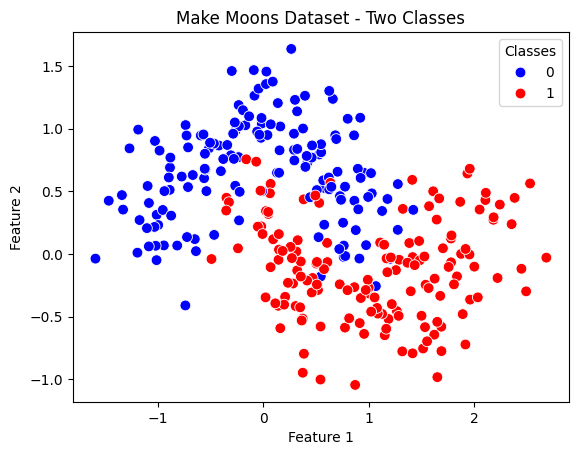

In [2]:
from sklearn.datasets import make_moons

import seaborn as sns


X, y = make_moons(n_samples=300, noise=0.25, random_state=42)

df = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])
df['Class'] = y

sns.scatterplot(
    data=df,
    x='Feature 1',
    y='Feature 2',
    hue='Class',
    palette={0: 'blue', 1: 'red'},
    s=60
)

plt.title('Make Moons Dataset - Two Classes')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(title='Classes')
plt.show()

In [ ]:


from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression



# Create pipeline
pipeline = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=5000))
])

# Define parameters to test
param_grid = {
    'poly__degree': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'logreg__C': [0.01, 0.1, 1, 10, 100]
}

# Cross-validation
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Train and find best parameters
grid_search.fit(X, y)

# Results
print("Best degree:", grid_search.best_params_['poly__degree'])
print("Best C:", grid_search.best_params_['logreg__C'])
print("Best CV accuracy:", grid_search.best_score_)

# Best model
best_model = grid_search.best_estimator_


Best degree: 6
Best C: 10
Best CV accuracy: 0.9066666666666666


In [4]:
from sklearn.preprocessing import PolynomialFeatures

In [5]:
poly  = PolynomialFeatures(degree=6)
X = poly.fit_transform(X)

In [6]:
X

array([[ 1.00000000e+00,  8.64395519e-01, -2.64509343e-01, ...,
         3.65753998e-03, -1.11922549e-03,  3.42488586e-04],
       [ 1.00000000e+00,  2.45115375e+00, -1.17549859e-01, ...,
         1.14717471e-03, -5.50150006e-05,  2.63835166e-06],
       [ 1.00000000e+00, -3.50712335e-01,  4.49211054e-01, ...,
         5.00845550e-03, -6.41509678e-03,  8.21679791e-03],
       ...,
       [ 1.00000000e+00, -7.29835719e-01,  9.45668886e-01, ...,
         4.25997088e-01, -5.51976535e-01,  7.15211687e-01],
       [ 1.00000000e+00,  1.43717801e+00, -8.85323265e-02, ...,
         1.26890361e-04, -7.81663707e-06,  4.81516599e-07],
       [ 1.00000000e+00, -3.43255651e-01,  8.70020922e-01, ...,
         6.75078344e-02, -1.71106370e-01,  4.33688772e-01]],
      shape=(300, 28))

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# y doit être un vecteur colonne (n, 1) pour correspondre à la sortie du modèle (n, 1)
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

In [8]:
def sigmoid(x):
    x = np.clip(x, -500, 500)  # évite le débordement de np.exp
    return 1 / (1 + np.exp(-x))

In [9]:
def initialisation(X):
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    return (W, b)


def modele(X, W, b):
    Z = X.dot(W) + b
    A = sigmoid(Z)
    return A

In [10]:
def log_loss(y, A, eps=1e-15):
    A = np.clip(A, eps, 1 - eps)  # évite log(0)
    return 1 / len(y) * np.sum(-y * np.log(A) - (1 - y) * np.log(1 - A))

In [11]:
def gradients(X, A, y):
    dW = 1 / len(y) * np.dot(X.T, A - y)
    db = 1 / len(y) * np.sum(A - y)
    return (dW, db)


def optimisation(X, W, b, A, y, learning_rate):
    dW, db = gradients(X, A, y)
    W = W - learning_rate * dW
    b = b - learning_rate * db
    return (W, b)

In [12]:
def predict(X, W, b, seuil=0.5):
    A = modele(X, W, b)
    return A >= seuil

In [13]:
def regression_logistique(X, y, learning_rate=0.1, n_iter=1000):
    # Initialisation
    W, b = initialisation(X)
    loss_history = []

    # Entraînement
    for i in range(n_iter):
        A = modele(X, W, b)
        loss_history.append(log_loss(y, A))
        W, b = optimisation(X, W, b, A, y, learning_rate=learning_rate)

    # Courbe de la fonction coût
    plt.plot(loss_history)
    plt.xlabel('n_iteration')
    plt.ylabel('Log_loss')
    plt.title('Evolution des erreurs')
    plt.show()
    return W, b

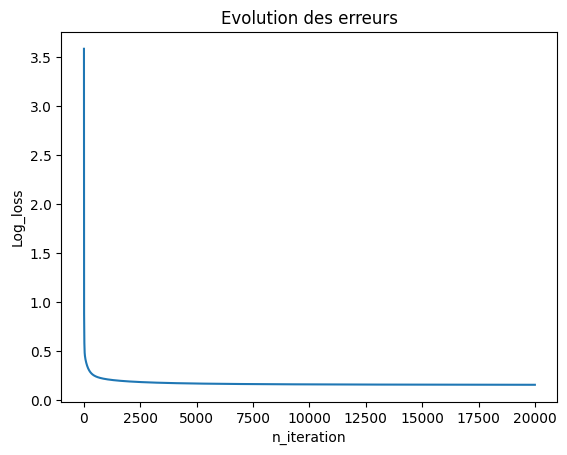

W = [ 2.06042838  0.16929235 -3.29160255 -7.23212769 -0.14263555  0.49984158
  1.73040558 -2.07969381  1.39726167 -1.79623014 -3.51772379 -0.60949923
 -0.20066801 -1.74613717 -2.47911035  2.59290109 -2.16837125  1.19255545
 -1.94627932 -0.53817206 -0.63195921  2.19241156  0.58462877 -1.27324176
 -0.43136549 -0.17578483 -1.03624943 -0.87502834] | b = [0.96307553]


In [14]:
W, b = regression_logistique(X_train, y_train  , n_iter=20000)
print('W =', W.ravel(), '| b =', b)

In [15]:
y_train_pred = predict(X_train, W, b)
y_test_pred = predict(X_test, W, b)

# Accuracy calculée à la main
acc_train = np.mean(y_train_pred == y_train)
acc_test = np.mean(y_test_pred == y_test)
print(f"Accuracy train : {acc_train:.2%}")
print(f"Accuracy test  : {acc_test:.2%}")

Accuracy train : 93.75%
Accuracy test  : 95.00%


Accuracy  : 95.00%
Precision : 91.89%
Recall    : 100.00%
F1-score  : 95.77%


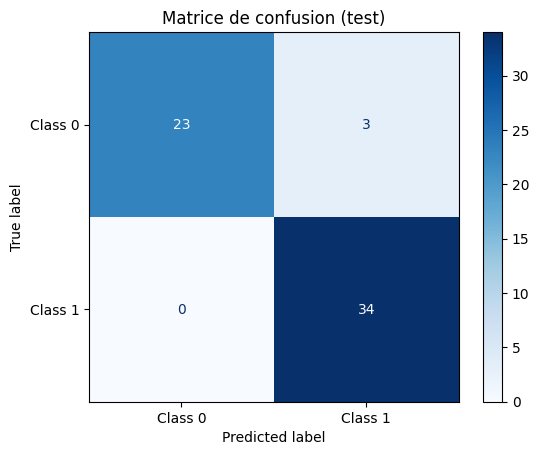

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

yt = y_test.ravel()
yp = y_test_pred.ravel().astype(int)

print(f"Accuracy  : {accuracy_score(yt, yp):.2%}")
print(f"Precision : {precision_score(yt, yp):.2%}")
print(f"Recall    : {recall_score(yt, yp):.2%}")
print(f"F1-score  : {f1_score(yt, yp):.2%}")

cm = confusion_matrix(yt, yp)
ConfusionMatrixDisplay(cm, display_labels=['Class 0', 'Class 1']).plot(cmap='Blues')
plt.title('Matrice de confusion (test)')
plt.show()

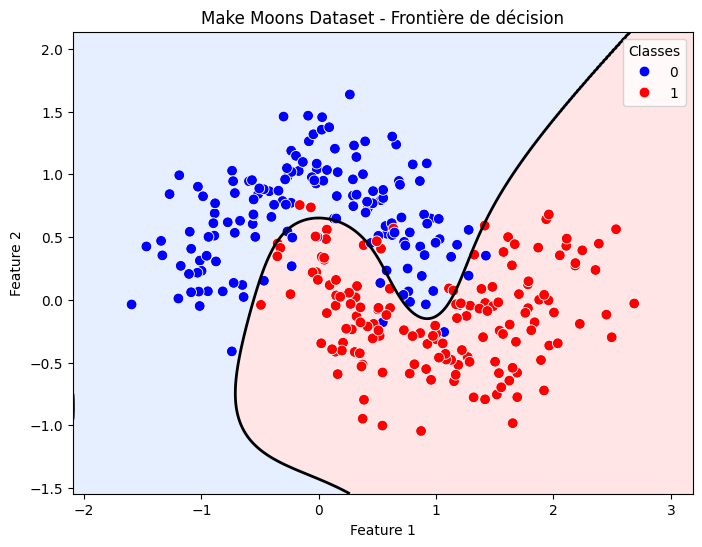

In [17]:
# Même graphique que le premier, avec la frontière de décision
x1_min, x1_max = df['Feature 1'].min() - 0.5, df['Feature 1'].max() + 0.5
x2_min, x2_max = df['Feature 2'].min() - 0.5, df['Feature 2'].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 400),
                     np.linspace(x2_min, x2_max, 400))

grid = poly.transform(np.c_[xx.ravel(), yy.ravel()])
Z = modele(grid, W, b).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, levels=[0, 0.5, 1], colors=['#cce0ff', '#ffcccc'], alpha=0.5)
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)  # ligne de séparation

sns.scatterplot(
    data=df,
    x='Feature 1',
    y='Feature 2',
    hue='Class',
    palette={0: 'blue', 1: 'red'},
    s=60
)

plt.title('Make Moons Dataset - Frontière de décision')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(title='Classes')
plt.show()